# Olist E-commerce Analysis

## Project Overview

This project analyzes the Olist Brazilian E-commerce Public Dataset to explore sales performance, product categories, delivery efficiency, and customer satisfaction.

The analysis identify business trends, evaluate key performance indicators, and derive actionable insights.

**Tools:** Python, Pandas, NumPy, Matplotlib, MySQL and JupyterLab.

## 1. Data Loading and Initial Inspection

In [2]:
from pathlib import Path

data_dir = Path("data")

print("Does the data folder exist?", data_dir.exists())
print("Files inside the data folder:")

for file in data_dir.iterdir():
    print(file.name)

Does the data folder exist? True
Files inside the data folder:
.ipynb_checkpoints
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [3]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("data")

orders = pd.read_csv(data_dir / "olist_orders_dataset.csv")
items = pd.read_csv(data_dir / "olist_order_items_dataset.csv")
customers = pd.read_csv(data_dir / "olist_customers_dataset.csv")
products = pd.read_csv(data_dir / "olist_products_dataset.csv")
reviews = pd.read_csv(data_dir / "olist_order_reviews_dataset.csv")
translation = pd.read_csv(data_dir / "product_category_name_translation.csv")

In [4]:
print("Orders:", orders.shape)
print("Items:", items.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Reviews:", reviews.shape)
print("Translation:", translation.shape)

Orders: (99441, 8)
Items: (112650, 7)
Customers: (99441, 5)
Products: (32951, 9)
Reviews: (99224, 7)
Translation: (71, 2)


In [5]:
print("ORDERS")
print(orders.columns.tolist())

print("\nITEMS")
print(items.columns.tolist())

print("\nCUSTOMERS")
print(customers.columns.tolist())

print("\nPRODUCTS")
print(products.columns.tolist())

print("\nREVIEWS")
print(reviews.columns.tolist())

print("\nTRANSLATION")
print(translation.columns.tolist())

ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

REVIEWS
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

TRANSLATION
['product_category_name', 'product_category_name_english']


In [6]:
dataframe = {
    "Orders": orders,
    "Items": items,
    "Customers": customers,
    "Products": products,
    "Reviews": reviews,
    "Translation": translation
}

for name, df in dataframe.items():
    print(f"\n*{name}*")
    print(df.info())


*Orders*
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB
None

*Items*
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_

## 2. Data Quality Assessment

In [7]:
missing_report = []

for name, df in dataframe.items():
    for col in df.columns:
        missing_count = df[col].isna().sum()

        missing_report.append({
            "table": name,
            "column": col,
            "missing_values": missing_count,
            "missing_percentage": round(
                (missing_count / len(df)) * 100, 2
            )
        })
missing_df = pd.DataFrame(missing_report)

missing_df = missing_df.sort_values(by = "missing_values", ascending = False)
missing_df

,table,column,missing_values,missing_percentage
32,Reviews,review_comment_title,87656,88.34
33,Reviews,review_comment_message,58247,58.70
6,Orders,order_delivered_customer_date,2965,2.98
5,Orders,order_delivered_carrier_date,1783,1.79
21,Products,product_category_name,610,1.85
23,Products,product_description_lenght,610,1.85
24,Products,product_photos_qty,610,1.85
22,Products,product_name_lenght,610,1.85
4,Orders,order_approved_at,160,0.16
27,Products,product_height_cm,2,0.01


In [8]:
duplicate_report = []

for name,df in dataframe.items():
    duplicate_report.append({
        "Table" : name,
        "Duplicate_rows" : df.duplicated().sum()
    })

duplicate_df = pd.DataFrame(duplicate_report)

duplicate_df

,Table,Duplicate_rows
0,Orders,0
1,Items,0
2,Customers,0
3,Products,0
4,Reviews,0
5,Translation,0


In [9]:
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors = "coerce")

orders[date_cols].dtypes

order_purchase_timestamp         datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [10]:
quality = []

for name,df in dataframe.items():
    quality.append({
       "tables" : name,
        "rows" : len(df),
        "columns" : len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum())
    })

quality_df = pd.DataFrame(quality)

quality_df

,tables,rows,columns,duplicate_rows,missing_cells
0,Orders,99441,8,0,4908
1,Items,112650,7,0,0
2,Customers,99441,5,0,0
3,Products,32951,9,0,2448
4,Reviews,99224,7,0,145903
5,Translation,71,2,0,0


In [11]:
# Creates a folder named "outputs" where data quality report "qulity_df" gets stored in csv format.
output_dir = Path("outputs")
output_dir.mkdir(parents = True , exist_ok = True)

quality_df.to_csv(output_dir / "data_quality_report.csv",
    index=False
)

## 3. Data Preparation and Order-Level Dataset Creation

In [12]:
# aggregating items DataFrame and creating new DataFrame named order_items.
order_items = (items.groupby("order_id", as_index = False).agg(item_sales=("price", "sum"),
        freight_value=("freight_value", "sum"),
        item_count=("order_item_id", "count")
    )
)

In [13]:
# aggregating reviews DataFrame and creating new DataFrame named order_reviews.
order_reviews = (
    reviews.groupby("order_id", as_index = False)
    .agg(
        review_score = ("review_score", "mean"),
        review_count = ("review_score", "count")
    )
)

In [14]:
# Merging orders, order_items, customers and order_reviews DataFrame to form new DataFrame named order_level.
order_level = (
    orders
    .merge(order_items, on="order_id", how="left")
    .merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
    .merge(order_reviews, on="order_id", how="left")
)

## 4. Delivery Performance Analysis

In [15]:
# Checking Delivered orders in order_level DataFrame.
delivered = order_level["order_status"].eq("delivered")

delivered.sum()

np.int64(96478)

In [16]:
# Checking if order is delivered but "order_delivered_customer_date" and "order_estimated_delivery_date" is not empty.
valid_delivery = (
    delivered
    & order_level["order_delivered_customer_date"].notna()
    & order_level["order_estimated_delivery_date"].notna()
)

valid_delivery.sum()

np.int64(96470)

In [17]:
# Creating new column named "late_delivery" by checking if "order_delivered_customer_date" >
# "order_estimated_delivery_date"
order_level["late_delivery"] = pd.NA

order_level.loc[valid_delivery, "late_delivery"] = (
    order_level.loc[valid_delivery, "order_delivered_customer_date"]
    > order_level.loc[valid_delivery, "order_estimated_delivery_date"]
)

In [18]:
order_level["late_delivery"].value_counts(dropna=False)

late_delivery
False    88644
True      7826
<NA>      2971
Name: count, dtype: int64

In [19]:
delivery = order_level.loc[valid_delivery].copy() # Creating new DataFrame "delivery" which contains only 
#valid_delivery information from "order_level" DataFrame.

# Creating Dataframe named "delivery_summary" to calculate delivery KPI.
delivery_summary = pd.DataFrame([{
    "delivered_orders_with_both_dates": len(delivery),
    "late_orders": int(delivery["late_delivery"].astype(bool).sum()),
    "late_delivery_rate_pct": round(
        100 * delivery["late_delivery"].astype(bool).mean(), 2
    )
}])

delivery_summary

,delivered_orders_with_both_dates,late_orders,late_delivery_rate_pct
0,96470,7826,8.11


In [20]:
# Converting DataFrame to csv.
delivery_summary.to_csv(
    output_dir / "delivery_kpi.csv",
    index = False
)

## 5. Customer Satisfaction Analysis

In [21]:
# Creating DataFrame named "review_summary" to ivestigate customer satisfaction.
review_summary = (
    order_level
    .dropna(subset = ["review_score"])
    .groupby("late_delivery", dropna = False, as_index = False)
    .agg(
        orders=("order_id", "nunique"),
        average_review_score=("review_score", "mean")
    )
)

review_summary

,late_delivery,orders,average_review_score
0,False,88163,4.294292
1,NaN,2849,1.753773
2,True,7661,2.566506


In [23]:
# coverting DataFrame to csv.
review_summary.to_csv(
    output_dir / "review_by_delivery_status.csv",
    index=False
)

## 6. Monthly Sales Analysis

In [24]:
# Creating DataFrame named "monthly" to calculate monthly sales KPI.
monthly = (
    order_level
    .dropna(subset=["order_purchase_timestamp"])
    .assign(
        month=lambda d: d["order_purchase_timestamp"]
        .dt.to_period("M").astype(str)
    )
    .groupby("month", as_index=False)
    .agg(
        item_sales=("item_sales", "sum"),
        orders=("order_id", "nunique")
    )
)

In [25]:
monthly.sort_values("item_sales", ascending = False).head()

,month,item_sales,orders
13,2017-11,1010271.37,7544
18,2018-04,996647.75,6939
19,2018-05,996517.68,6873
17,2018-03,983213.44,7211
15,2018-01,950030.36,7269


In [26]:
# Convverting DataFrame to csv.
monthly.to_csv(output_dir/ "monthly_sales.csv", index = False)

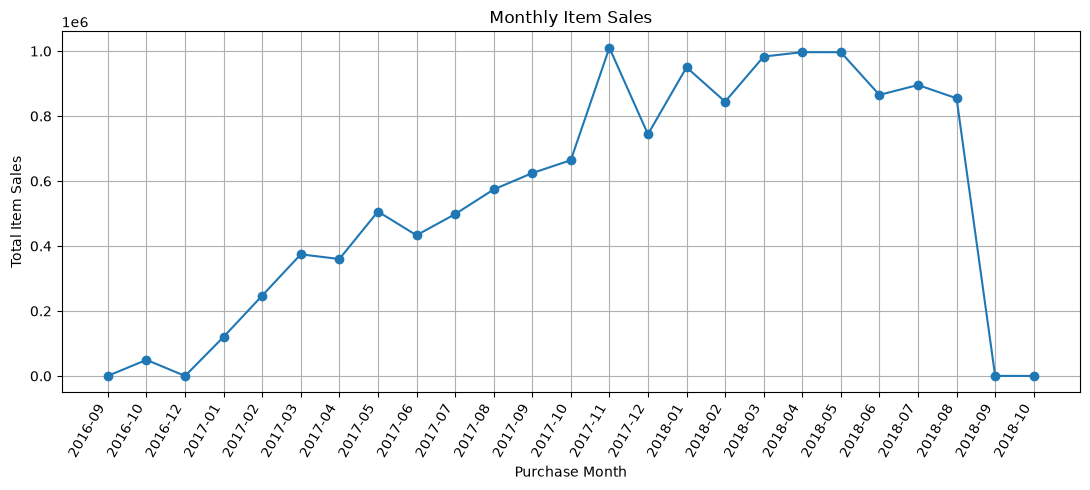

In [27]:
# Code to create chart that shows monthly sales.
plt.figure(figsize=(11, 5))

plt.plot(monthly["month"],monthly["item_sales"],marker="o")
plt.title("Monthly Item Sales")
plt.xlabel("Purchase Month")
plt.ylabel("Total Item Sales")
plt.grid(True)
plt.xticks(rotation=60, ha="right")
plt.tight_layout()

plt.savefig(output_dir / "monthly_item_sales.png", dpi=160)
plt.show()
plt.close()

## 7. Product Category Sales Analysis

In [28]:
# Converts "product_category_name" column in products DataFrame from portuguese to english language.
products = products.merge(
    translation,
    on="product_category_name",
    how="left"
)

products["category"] = (
    products["product_category_name_english"]
    .fillna(products["product_category_name"])
    .fillna("unknown")
)

In [29]:
item_product = items.merge(
    products[["product_id","category"]],
    on = "product_id",
    how = "left"
)

In [30]:
category_sales = (
    item_product
    .groupby("category", dropna = False, as_index = False)
    .agg(
        item_sales = ("price", "sum"),
        item_count = ("product_id", "count")
    )
    .sort_values("item_sales", ascending = False)
)

category_sales.head()

,category,item_sales,item_count
43,health_beauty,1258681.34,9670
73,watches_gifts,1205005.68,5991
7,bed_bath_table,1036988.68,11115
67,sports_leisure,988048.97,8641
15,computers_accessories,911954.32,7827


In [31]:
category_sales.to_csv(output_dir/"category_sales.csv", index = False)

In [32]:
top_categories = (
    category_sales
    .head(10)
    .sort_values("item_sales")
)
top_categories

,category,item_sales,item_count
42,garden_tools,485256.46,4347
5,auto,592720.11,4235
49,housewares,632248.66,6964
20,cool_stuff,635290.85,3796
39,furniture_decor,729762.49,8334
15,computers_accessories,911954.32,7827
67,sports_leisure,988048.97,8641
7,bed_bath_table,1036988.68,11115
73,watches_gifts,1205005.68,5991
43,health_beauty,1258681.34,9670


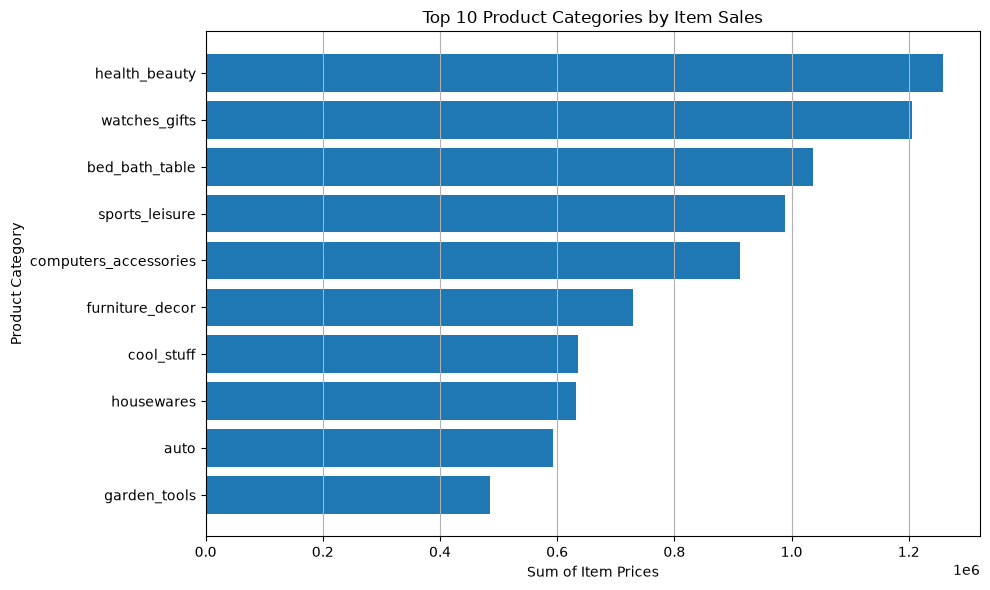

In [33]:

plt.figure(figsize=(10, 6))

plt.barh(top_categories["category"].astype(str),top_categories["item_sales"])

plt.title("Top 10 Product Categories by Item Sales")
plt.xlabel("Sum of Item Prices")
plt.ylabel("Product Category")
plt.grid(axis = "x")
plt.tight_layout()

plt.savefig(output_dir/"top_category.png", dpi = 160)
plt.show()
plt.close()

## 8. State-wise Order Analysis

In [34]:
states = (
    order_level
    .groupby("customer_state", as_index = False)
    .agg(
        orders = ("order_id", "nunique"),
        item_sales = ("item_sales", "sum")
    )
    .sort_values("orders", ascending = False)
)
states.head(10)

,customer_state,orders,item_sales
25,SP,41746,5202955.05
18,RJ,12852,1824092.67
10,MG,11635,1585308.03
22,RS,5466,750304.02
17,PR,5045,683083.76
23,SC,3637,520553.34
4,BA,3380,511349.99
6,DF,2140,302603.94
7,ES,2033,275037.31
8,GO,2020,294591.95


In [35]:
states.to_csv(output_dir/"state_performance.csv", index = False)

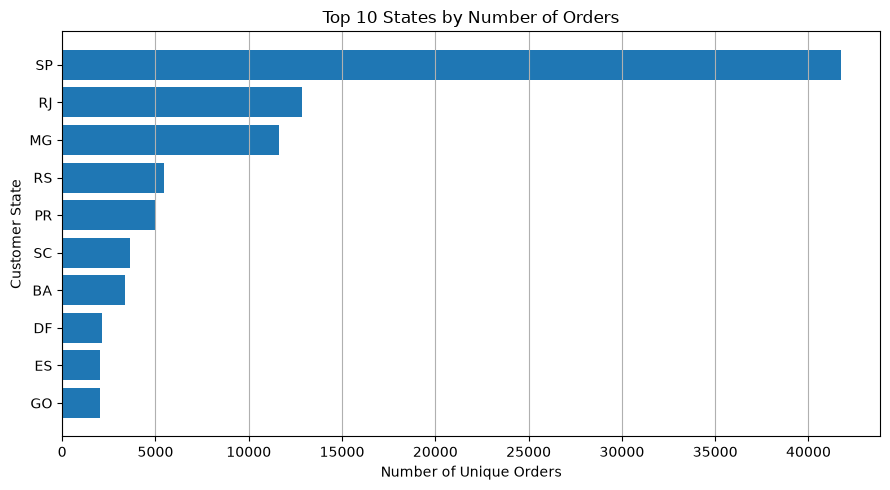

In [36]:
top_states = states.head(10).sort_values("orders")

plt.figure(figsize = (9, 5))

plt.barh(top_states["customer_state"].astype(str), top_states["orders"])
plt.title("Top 10 States by Number of Orders")
plt.xlabel("Number of Unique Orders")
plt.ylabel("Customer State")
plt.grid(axis = "x")
plt.tight_layout()

plt.savefig(output_dir/"top_state_by_orders.png", dpi = 160)
plt.show()
plt.close()

In [37]:
order_level.to_csv(output_dir/"order_level_analysis.csv", index = False)

## 9. Final Analysis Summary

In [38]:
print("1. DELIVERY KPI")
display(delivery_summary)

print("\n2. REVIEW SCORES BY DELIVERY STATUS")
display(review_summary)

print("\n3. TOP 5 MONTHS BY ITEM SALES")
display(
    monthly.sort_values(
        "item_sales", ascending=False
    ).head(5)
)

print("\n4. TOP 10 PRODUCT CATEGORIES")
display(category_sales.head(10))

print("\n5. TOP 10 STATES BY ORDERS")
display(states.head(10))

1. DELIVERY KPI


,delivered_orders_with_both_dates,late_orders,late_delivery_rate_pct
0,96470,7826,8.11



2. REVIEW SCORES BY DELIVERY STATUS


,late_delivery,orders,average_review_score
0,False,88163,4.294292
1,NaN,2849,1.753773
2,True,7661,2.566506



3. TOP 5 MONTHS BY ITEM SALES


,month,item_sales,orders
13,2017-11,1010271.37,7544
18,2018-04,996647.75,6939
19,2018-05,996517.68,6873
17,2018-03,983213.44,7211
15,2018-01,950030.36,7269



4. TOP 10 PRODUCT CATEGORIES


,category,item_sales,item_count
43,health_beauty,1258681.34,9670
73,watches_gifts,1205005.68,5991
7,bed_bath_table,1036988.68,11115
67,sports_leisure,988048.97,8641
15,computers_accessories,911954.32,7827
39,furniture_decor,729762.49,8334
20,cool_stuff,635290.85,3796
49,housewares,632248.66,6964
5,auto,592720.11,4235
42,garden_tools,485256.46,4347



5. TOP 10 STATES BY ORDERS


,customer_state,orders,item_sales
25,SP,41746,5202955.05
18,RJ,12852,1824092.67
10,MG,11635,1585308.03
22,RS,5466,750304.02
17,PR,5045,683083.76
23,SC,3637,520553.34
4,BA,3380,511349.99
6,DF,2140,302603.94
7,ES,2033,275037.31
8,GO,2020,294591.95


# Business Insights

## 1. Delivery performance

### Late-delivery rate  
 8.11%                   

### Late orders
 7,826


96,470 delivered orders had both estimated_delivery_date and order_delivered_date available.

**Business insight:** Approximately 8.11% of eligible delivered orders arrived later than their estimated delivery dates.This indicates that most eligible orders were delivered on time or early, although late deliveries remain an area for improvement.

## 2. Customer satisfaction and delivery status

**Business insight:** Orders delivered late received substantially lower average review scores (2.57) than orders delivered on time or early (4.29).
This suggests a strong association between delivery delays and lower customer satisfaction. However, this comparison alone does not prove that delays caused the lower ratings.


## 3. Monthly Sales Performance

**Business insight:** November 2017 recorded the highest monthly item sales among the months in this dataset, at approximately 1.01 million.
April and May 2018 also performed strongly, with sales close to one million each.

## 4. Product Category Performance

**Business insight:** Health & beauty generated the highest item sales among the product categories, followed by watches & gifts and bed, bath & table.
This suggests that these categories are important contributors to the store's sales.

## 5. State-wise Order Performance

**Business insight:** São Paulo (SP) dominates the results, generating 41,746 orders and approximately 5.2 million in item sales. Rio de Janeiro (RJ) and Minas Gerais (MG) follow.

This suggests that São Paulo is a particularly important market for the business.